# Punto 1: clasificacion de parches de imagen con aprendizaje no supervisado

1. Inventario, deteccion de duplicados y agrupacion por escenas.
2. Separacion de escenas en un pool de entrenamiento y un conjunto de prueba.
3. Extraccion de parches `64 x 64` reales en escala de grises, sin PCA.
4. Agrupacion con `MiniBatchKMeans` y eleccion de `k` por codo y silueta.
5. **Etiquetado interactivo de los parches representativos de cada cluster.**
6. **Etiquetado interactivo del conjunto de prueba.**
7. Propagacion semi-supervisada y clasificacion con regresion logistica.
8. Aprendizaje activo con las muestras de menor confianza.
9. Figuras, metricas y resumen final.

In [1]:
from pathlib import Path
import io
import hashlib
import json
import math
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
from matplotlib.ticker import FixedFormatter, FixedLocator
from matplotlib.patches import Rectangle
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    silhouette_samples,
    silhouette_score,
)
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

try:
    import pillow_heif

    pillow_heif.register_heif_opener()
    HEIF_DISPONIBLE = True
except Exception:
    HEIF_DISPONIBLE = False

try:
    import ipywidgets as widgets
    from IPython.display import clear_output, display

    WIDGETS_DISPONIBLES = True
except Exception:
    WIDGETS_DISPONIBLES = False

EXTENSIONES_IMAGEN = {".heic", ".jpg", ".jpeg", ".png"}

RAIZ = Path.cwd()
if not (RAIZ / "punto1_contaminacion_notebook.py").exists():
    RAIZ = Path("/home/zahir/SIS420-LABS/part2")

CARPETA_IMAGENES = RAIZ / "maria_luciana_salinas_vilar"

MODO_PRUEBA = False

TAM_PARCHE = 64
MAX_PARCHES_POR_IMAGEN = 64
MIN_STD_PARCHE = 5.0
SEMILLA = 42
K_MIN = 2
K_MAX = 12
TEST_SIZE = 0.2
MUESTRA_SILUETA = 2000
FRAC_INCIERTAS = 0.2
PARCHES_TEST_POR_CLUSTER = 12
REPETICIONES_ACTIVO = 5
GAP_ESCENA = 120
UMBRAL_DUPLICADO = 1
CLASES_SUGERIDAS = [
    "terreno",
    "roca",
    "rama",
    "lata",
    "vegetacion",
    "agua",
    "muro",
]

if MODO_PRUEBA:
    SALIDA = Path("/tmp/opencode/resultados_punto1_v2_prueba")
    MAX_IMAGENES = 40
    PARCHES_POR_IMAGEN = 8
    K_MIN = 2
    K_MAX = 3
    MUESTRA_SILUETA = 500
    PARCHES_TEST_POR_CLUSTER = 6
    REPETICIONES_ACTIVO = 1
    SIN_CACHE = True
else:
    SALIDA = RAIZ / "resultados_punto1_v2"
    MAX_IMAGENES = None
    PARCHES_POR_IMAGEN = MAX_PARCHES_POR_IMAGEN
    K_MIN = 2
    K_MAX = 12
    MUESTRA_SILUETA = 2000
    PARCHES_TEST_POR_CLUSTER = 12
    REPETICIONES_ACTIVO = 5
    SIN_CACHE = False

FIGURAS = SALIDA / "figuras"
CACHE = SALIDA / "cache"
ETIQUETAS_REPRESENTANTES = SALIDA / "etiquetas_representantes.csv"
ETIQUETAS_TEST = SALIDA / "etiquetas_test.csv"
SALIDA.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})


def guardar_fig(ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(ruta, bbox_inches="tight")
    print(f"Figura guardada en: {ruta}")
    return ruta


print(f"Modo de prueba: {MODO_PRUEBA}")
print(f"Carpeta de imagenes: {CARPETA_IMAGENES}")
print(f"Salida: {SALIDA}")
print(f"Parches por imagen: {PARCHES_POR_IMAGEN}")
print(f"Tamano de parche: {TAM_PARCHE}x{TAM_PARCHE} en escala de grises")
print(f"HEIF disponible: {HEIF_DISPONIBLE}")
print(f"Widgets disponibles: {WIDGETS_DISPONIBLES}")

Modo de prueba: False
Carpeta de imagenes: /home/zahir/SIS420-LABS/part2/maria_luciana_salinas_vilar
Salida: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2
Parches por imagen: 64
Tamano de parche: 64x64 en escala de grises
HEIF disponible: True
Widgets disponibles: True


## Mapa del cuadernillo

- **Inventario:** carga las imagenes, detecta duplicados y agrupa por escena.
- **Pool y prueba:** separa escenas completas para evaluar sin fugas de datos.
- **Parches:** extrae parches reales `64 x 64` en escala de grises.
- **MiniBatchKMeans:** elige `k` por codo y silueta, y obtiene un representante
  por cluster.
- **Etiquetado interactivo:** etiqueta los representantes y el conjunto de prueba.
- **Semi-supervisado:** propaga la clase del representante a todo el cluster.
- **Aprendizaje activo:** entrena con las muestras de menor confianza.

## 1. Funciones de inventario y carga de imagenes

In [2]:
def cargar_rgb(ruta):
    ruta = Path(ruta)
    with Image.open(ruta) as img:
        img = ImageOps.exif_transpose(img)
        return img.convert("RGB")


def cargar_escala_grises(ruta):
    ruta = Path(ruta)
    with Image.open(ruta) as img:
        img = ImageOps.exif_transpose(img)
        return img.convert("L")


def leer_fecha(img, ruta):
    exif = img.getexif()
    for clave in (36867, 306):
        valor = exif.get(clave)
        if valor:
            texto = str(valor).strip()
            for formato in ("%Y:%m:%d %H:%M:%S", "%Y-%m-%d %H:%M:%S"):
                try:
                    return datetime.strptime(texto, formato)
                except ValueError:
                    pass
    return datetime.fromtimestamp(Path(ruta).stat().st_mtime)


def hash_promedio(img):
    pequena = img.convert("L").resize((8, 8), Image.Resampling.LANCZOS)
    arreglo = np.asarray(pequena, dtype=np.float32)
    return (arreglo > arreglo.mean()).reshape(-1)


def distancia_hamming(a, b):
    return int(np.count_nonzero(a != b))


def inventariar(carpeta, umbral_duplicado=UMBRAL_DUPLICADO, gap_escena=GAP_ESCENA):
    carpeta = Path(carpeta)
    archivos = sorted(
        p
        for p in carpeta.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONES_IMAGEN
    )

    registros = []
    duplicados = []
    hashes = []
    total = len(archivos)

    for posicion, ruta in enumerate(archivos, start=1):
        img = cargar_rgb(ruta)
        fecha = leer_fecha(img, ruta)
        huella = hash_promedio(img)

        duplicado_de = None
        for anterior_huella, anterior_nombre in hashes:
            if distancia_hamming(huella, anterior_huella) <= umbral_duplicado:
                duplicado_de = anterior_nombre
                break

        if duplicado_de is not None:
            duplicados.append(
                {
                    "archivo": ruta.name,
                    "duplicado_de": duplicado_de,
                    "fecha": fecha.strftime("%Y-%m-%d %H:%M:%S"),
                }
            )
        else:
            hashes.append((huella, ruta.name))
            registros.append(
                {
                    "archivo": ruta.name,
                    "ruta": str(ruta),
                    "fecha": fecha.strftime("%Y-%m-%d %H:%M:%S"),
                    "fecha_dt": fecha,
                }
            )

        if posicion % 20 == 0 or posicion == total:
            print(f"Inventario: {posicion}/{total} archivos procesados")

    registros.sort(key=lambda r: r["fecha_dt"])
    escena = -1
    fecha_anterior = None
    for registro in registros:
        fecha = registro["fecha_dt"]
        if (
            fecha_anterior is None
            or (fecha - fecha_anterior).total_seconds() > gap_escena
        ):
            escena += 1
        registro["escena"] = escena
        fecha_anterior = fecha

    df = pd.DataFrame(registros)
    df = df.drop(columns=["fecha_dt"])
    df_duplicados = pd.DataFrame(duplicados)
    return df, df_duplicados

## 2. Inventario y separacion por escenas

In [3]:
df_inventario, df_duplicados = inventariar(
    CARPETA_IMAGENES,
    umbral_duplicado=UMBRAL_DUPLICADO,
    gap_escena=GAP_ESCENA,
)
df_inventario.to_csv(SALIDA / "inventario.csv", index=False, encoding="utf-8")
if not df_duplicados.empty:
    df_duplicados.to_csv(SALIDA / "duplicados.csv", index=False, encoding="utf-8")

df = df_inventario.copy()
if MAX_IMAGENES is not None:
    df = df.sample(n=min(MAX_IMAGENES, len(df)), random_state=SEMILLA).copy()
    df = df.sort_values("fecha").reset_index(drop=True)

divisor = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEMILLA)
indices_pool, indices_test = next(divisor.split(df, groups=df["escena"]))
df_pool = df.iloc[indices_pool].reset_index(drop=True)
df_test = df.iloc[indices_test].reset_index(drop=True)

print("Division por escenas")
print(f"Imagenes unicas          : {len(df)}")
print(f"Escenas en el pool       : {df_pool['escena'].nunique()}")
print(f"Escenas en prueba        : {df_test['escena'].nunique()}")
print(f"Imagenes en el pool      : {len(df_pool)}")
print(f"Imagenes en prueba       : {len(df_test)}")

Inventario: 20/181 archivos procesados
Inventario: 40/181 archivos procesados
Inventario: 60/181 archivos procesados
Inventario: 80/181 archivos procesados
Inventario: 100/181 archivos procesados
Inventario: 120/181 archivos procesados
Inventario: 140/181 archivos procesados
Inventario: 160/181 archivos procesados
Inventario: 180/181 archivos procesados
Inventario: 181/181 archivos procesados
Division por escenas
Imagenes unicas          : 173
Escenas en el pool       : 8
Escenas en prueba        : 3
Imagenes en el pool      : 136
Imagenes en prueba       : 37


## 3. Extraccion de parches en escala de grises

Cada imagen se divide en una grilla de regiones y de cada region se toma un
recorte real de `64 x 64` pixeles en escala de grises, sin redimensionar la
imagen completa. Asi el parche conserva el detalle original.

In [4]:
def extraer_parches_imagen(ruta, n_parches, semilla, min_std):
    img = cargar_escala_grises(ruta)
    arreglo = np.asarray(img, dtype=np.uint8)
    alto, ancho = arreglo.shape

    lado = int(math.ceil(math.sqrt(n_parches)))
    rng = np.random.default_rng(semilla)

    parches = []
    coordenadas = []
    for ry in range(lado):
        for rx in range(lado):
            y0 = int(ry * alto / lado)
            y1 = int((ry + 1) * alto / lado)
            x0 = int(rx * ancho / lado)
            x1 = int((rx + 1) * ancho / lado)

            max_y = y1 - TAM_PARCHE
            max_x = x1 - TAM_PARCHE
            if max_y <= y0 or max_x <= x0:
                cy = max(0, (y0 + y1 - TAM_PARCHE) // 2)
                cx = max(0, (x0 + x1 - TAM_PARCHE) // 2)
            else:
                cy = int(rng.integers(y0, max_y + 1))
                cx = int(rng.integers(x0, max_x + 1))

            parche = arreglo[cy : cy + TAM_PARCHE, cx : cx + TAM_PARCHE]
            if parche.shape != (TAM_PARCHE, TAM_PARCHE):
                continue
            if float(parche.std()) >= min_std:
                parches.append(parche.reshape(-1).copy())
                coordenadas.append((cy, cx))

    if not parches:
        for ry in range(lado):
            for rx in range(lado):
                y0 = int(ry * alto / lado)
                y1 = int((ry + 1) * alto / lado)
                x0 = int(rx * ancho / lado)
                x1 = int((rx + 1) * ancho / lado)
                parche = arreglo[y0 : y0 + TAM_PARCHE, x0 : x0 + TAM_PARCHE]
                if parche.shape == (TAM_PARCHE, TAM_PARCHE):
                    parches.append(parche.reshape(-1).copy())
                    coordenadas.append((y0, x0))

    if len(parches) > n_parches:
        elegidos = np.sort(rng.choice(len(parches), size=n_parches, replace=False))
        parches = [parches[i] for i in elegidos]
        coordenadas = [coordenadas[i] for i in elegidos]

    x = np.asarray(parches, dtype=np.float32) / 255.0
    coords = np.asarray(coordenadas, dtype=np.int32)
    return x, coords


def construir_matriz(df, n_parches, min_std, semilla):
    partes_x = []
    archivos = []
    partes_coords = []

    for posicion, fila in df.iterrows():
        x, coords = extraer_parches_imagen(
            fila["ruta"],
            n_parches=n_parches,
            semilla=semilla + posicion,
            min_std=min_std,
        )
        partes_x.append(x)
        archivos.extend([fila["archivo"]] * len(x))
        partes_coords.append(coords)

    x_total = np.vstack(partes_x).astype(np.float32)
    archivos_total = np.asarray(archivos)
    coords_total = np.vstack(partes_coords)
    return x_total, archivos_total, coords_total


def clave_cache(lista_archivos, parametros):
    texto = ",".join(lista_archivos) + repr(sorted(parametros.items()))
    return hashlib.sha1(texto.encode("utf-8")).hexdigest()[:16]


def cargar_o_construir_matriz(df, cache_dir, n_parches, min_std, semilla, usar_cache):
    parametros = {
        "tam_parche": TAM_PARCHE,
        "n_parches": int(n_parches),
        "min_std": float(min_std),
        "semilla": int(semilla),
        "n_imagenes": int(len(df)),
    }
    ruta_cache = (
        Path(cache_dir)
        / f"parches_{clave_cache(df['archivo'].astype(str), parametros)}.npz"
    )
    ruta_cache.parent.mkdir(parents=True, exist_ok=True)

    if usar_cache and ruta_cache.exists():
        datos = np.load(ruta_cache, allow_pickle=False)
        print(f"Cache cargado desde: {ruta_cache}")
        return datos["X"], datos["archivos"], datos["coords"]

    x_total, archivos_total, coords_total = construir_matriz(
        df, n_parches=n_parches, min_std=min_std, semilla=semilla
    )
    if usar_cache:
        np.savez_compressed(
            ruta_cache,
            X=x_total,
            archivos=archivos_total,
            coords=coords_total,
        )
        print(f"Cache guardado en: {ruta_cache}")
    return x_total, archivos_total, coords_total

## 4. Construccion de las matrices de parches

In [5]:
X_pool, archivos_pool, coords_pool = cargar_o_construir_matriz(
    df_pool,
    cache_dir=CACHE,
    n_parches=PARCHES_POR_IMAGEN,
    min_std=MIN_STD_PARCHE,
    semilla=SEMILLA,
    usar_cache=not SIN_CACHE,
)
X_test, archivos_test, coords_test = cargar_o_construir_matriz(
    df_test,
    cache_dir=CACHE,
    n_parches=PARCHES_POR_IMAGEN,
    min_std=MIN_STD_PARCHE,
    semilla=SEMILLA + 1000,
    usar_cache=not SIN_CACHE,
)

print("Matrices de parches")
print(f"X_pool: {X_pool.shape} | X_test: {X_test.shape}")
print(f"Caracteristicas por parche: {TAM_PARCHE * TAM_PARCHE}")
print(
    f"Verificacion 64x64: cada parche es {TAM_PARCHE}x{TAM_PARCHE} pixeles "
    f"aplanados a {TAM_PARCHE * TAM_PARCHE} valores (columna por parche = "
    f"{X_pool.shape[1]})"
)

Cache cargado desde: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/cache/parches_aa00876aaf7c123a.npz
Cache cargado desde: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/cache/parches_6fcc358c04ac04a7.npz
Matrices de parches
X_pool: (8581, 4096) | X_test: (2277, 4096)
Caracteristicas por parche: 4096
Verificacion 64x64: cada parche es 64x64 pixeles aplanados a 4096 valores (columna por parche = 4096)


## 5. MiniBatchKMeans: seleccion de k

Se entrena `MiniBatchKMeans` directamente sobre los pixeles crudos en escala de
grises. El numero de clusters se elige con el metodo del codo (inercia) y el
indice de silueta.

In [6]:
def nuevo_minibatch(k, semilla, n_muestras):
    return MiniBatchKMeans(
        n_clusters=k,
        random_state=semilla,
        batch_size=int(min(2048, max(1, n_muestras))),
        n_init=3,
        max_iter=200,
        reassignment_ratio=0.0,
    )


def evaluar_k(x, k_min, k_max, semilla, muestra_silueta):
    k_max = int(min(k_max, len(x) - 1))
    k_min = int(max(2, k_min))
    if k_max < k_min:
        raise RuntimeError("No hay suficientes muestras para evaluar K-Means")

    filas = []
    for k in range(k_min, k_max + 1):
        modelo = nuevo_minibatch(k, semilla, len(x)).fit(x)
        etiquetas = modelo.predict(x)
        tam = int(min(muestra_silueta, len(x)))
        silueta = float(
            silhouette_score(x, etiquetas, sample_size=tam, random_state=semilla)
        )
        filas.append({"k": k, "inercia": float(modelo.inertia_), "silueta": silueta})
        print(f"k={k:2d} | inercia={modelo.inertia_:.2f} | silueta={silueta:.4f}")

    df = pd.DataFrame(filas)
    mejor_k = int(df.loc[df["silueta"].idxmax(), "k"])
    return df, mejor_k


def graficar_seleccion_k(df, mejor_k, ruta):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(df["k"], df["silueta"], "o-", color="#4c72b0")
    axes[0].axvline(
        mejor_k, color="#c44e52", linestyle="--", label=f"mejor k={mejor_k}"
    )
    axes[0].set_xlabel("Numero de clusters k")
    axes[0].set_ylabel("Indice de Silueta")
    axes[0].set_title("Silueta vs k")
    axes[0].legend()
    axes[1].plot(df["k"], df["inercia"], "s-", color="#55a868")
    axes[1].axvline(
        mejor_k, color="#c44e52", linestyle="--", label=f"mejor k={mejor_k}"
    )
    axes[1].set_xlabel("Numero de clusters k")
    axes[1].set_ylabel("Inercia")
    axes[1].set_title("Inercia vs k")
    axes[1].legend()
    plt.tight_layout()
    return guardar_fig(ruta)

In [7]:
df_k, mejor_k = evaluar_k(X_pool, K_MIN, K_MAX, SEMILLA, MUESTRA_SILUETA)
k = max(int(mejor_k), 2)
k = min(k, len(X_pool) - 1)
df_k.to_csv(SALIDA / "seleccion_k.csv", index=False, encoding="utf-8")

print(f"\nk elegido: {k}")

k= 2 | inercia=1531890.75 | silueta=0.2557
k= 3 | inercia=1388298.00 | silueta=0.1609
k= 4 | inercia=1315930.50 | silueta=0.1127
k= 5 | inercia=1291937.12 | silueta=0.1054
k= 6 | inercia=1284495.00 | silueta=0.1069
k= 7 | inercia=1268657.25 | silueta=0.0821
k= 8 | inercia=1238244.25 | silueta=0.0579
k= 9 | inercia=1251577.12 | silueta=0.0601
k=10 | inercia=1216362.88 | silueta=0.0308
k=11 | inercia=1224115.62 | silueta=0.0384
k=12 | inercia=1236083.75 | silueta=0.0611

k elegido: 2


## 6. Entrenamiento final y representantes

In [8]:
def graficar_diagrama_silueta(x, etiquetas, k, silueta_promedio, ruta, muestra):
    rng = np.random.default_rng(SEMILLA)
    cantidad = min(muestra, len(x))
    sub = np.sort(rng.choice(len(x), size=cantidad, replace=False))
    coeficientes = silhouette_samples(x[sub], etiquetas[sub])
    etiquetas_sub = etiquetas[sub]
    padding = max(1, cantidad // 40)
    posicion = padding
    ticks = []
    fig, ax = plt.subplots(figsize=(9, max(5, 0.45 * k + 3)))
    for cluster in range(k):
        valores = np.sort(coeficientes[etiquetas_sub == cluster])
        color = plt.cm.Spectral(cluster / max(k - 1, 1))
        ax.fill_betweenx(
            np.arange(posicion, posicion + len(valores)),
            0,
            valores,
            facecolor=color,
            edgecolor=color,
            alpha=0.75,
        )
        ticks.append(posicion + len(valores) // 2)
        posicion += len(valores) + padding
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_major_formatter(FixedFormatter([str(i) for i in range(k)]))
    ax.axvline(
        silueta_promedio,
        color="#c44e52",
        linestyle="--",
        label=f"promedio={silueta_promedio:.3f}",
    )
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_ylabel("Cluster")
    ax.set_title(f"Diagrama de silueta para k={k}")
    ax.legend(loc="lower right")
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_centroides(modelo, ruta):
    cantidad_clusters = modelo.n_clusters
    columnas = min(6, cantidad_clusters)
    filas = int(math.ceil(cantidad_clusters / columnas))
    fig, axes = plt.subplots(
        filas, columnas, figsize=(2.6 * columnas, 2.6 * filas), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for cluster in range(cantidad_clusters):
        ax = axes.ravel()[cluster]
        centroide = modelo.cluster_centers_[cluster].reshape(TAM_PARCHE, TAM_PARCHE)
        ax.imshow(centroide, cmap="gray")
        ax.set_title(
            f"Cluster {cluster}\nn={int((modelo.labels_ == cluster).sum())}",
            fontsize=8,
        )
    plt.suptitle("Centroides (parche promedio) por cluster", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_tamanos_cluster(etiquetas, ruta):
    conteo = pd.Series(etiquetas).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(conteo.index.astype(str), conteo.values, color="#4c72b0")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Numero de parches")
    ax.set_title("Tamano de cada cluster")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return guardar_fig(ruta)


def obtener_representantes(modelo, x):
    distancias = modelo.transform(x)
    etiquetas = modelo.labels_
    indices = []
    for cluster in range(modelo.n_clusters):
        miembros = np.where(etiquetas == cluster)[0]
        if len(miembros) == 0:
            indices.append(-1)
        else:
            indices.append(int(miembros[np.argmin(distancias[miembros, cluster])]))
    return np.asarray(indices, dtype=int)


def graficar_parches_por_cluster(x_plano, etiquetas_cluster, ruta, cantidad=8):
    k = int(etiquetas_cluster.max()) + 1
    rng = np.random.default_rng(SEMILLA)
    fig, axes = plt.subplots(
        k, cantidad, figsize=(3.0 * cantidad, 2.6 * k), squeeze=False
    )
    for cluster in range(k):
        miembros = np.where(etiquetas_cluster == cluster)[0]
        elegidos = miembros
        if len(miembros) > cantidad:
            elegidos = np.sort(rng.choice(miembros, size=cantidad, replace=False))
        for rank in range(cantidad):
            ax = axes[cluster, rank]
            ax.axis("off")
            if rank < len(elegidos):
                ax.imshow(
                    x_plano[elegidos[rank]].reshape(TAM_PARCHE, TAM_PARCHE),
                    cmap="gray",
                )
        axes[cluster, 0].set_ylabel(f"Cluster {cluster}", fontsize=9)
    plt.suptitle("Parches de ejemplo por cluster", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_representantes(x_plano, indices, etiquetas, ruta):
    validos = [
        (i, idx, etiqueta)
        for i, (idx, etiqueta) in enumerate(zip(indices, etiquetas))
        if idx >= 0
    ]
    if not validos:
        return None
    columnas = min(6, len(validos))
    filas = int(math.ceil(len(validos) / columnas))
    fig, axes = plt.subplots(
        filas, columnas, figsize=(2.8 * columnas, 2.8 * filas), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (cluster, idx, etiqueta) in zip(axes.ravel(), validos):
        ax.imshow(x_plano[idx].reshape(TAM_PARCHE, TAM_PARCHE), cmap="gray")
        ax.set_title(f"Cluster {cluster}\n{etiqueta}", fontsize=8)
    plt.suptitle("Parches representativos de cada cluster", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_contexto_representantes(df_reps, x_plano, carpeta, ruta):
    filas = len(df_reps)
    fig, axes = plt.subplots(filas, 2, figsize=(11, 2.8 * filas), squeeze=False)
    for i, (_, fila) in enumerate(df_reps.iterrows()):
        parche = (
            x_plano[int(fila["indice"])].reshape(TAM_PARCHE, TAM_PARCHE) * 255
        ).astype(np.uint8)
        imagen = np.asarray(
            cargar_escala_grises(Path(carpeta) / str(fila["archivo"])),
            dtype=np.uint8,
        )
        y, x = int(fila["y"]), int(fila["x"])
        axes[i, 0].imshow(parche, cmap="gray")
        axes[i, 0].set_title(f"C{int(fila['cluster'])} | {fila['clase']}", fontsize=9)
        axes[i, 0].axis("off")
        axes[i, 1].imshow(imagen, cmap="gray")
        axes[i, 1].add_patch(
            Rectangle(
                (x, y),
                TAM_PARCHE,
                TAM_PARCHE,
                fill=False,
                edgecolor="red",
                linewidth=3,
            )
        )
        axes[i, 1].set_title(str(fila["archivo"]), fontsize=8)
        axes[i, 1].axis("off")
    plt.suptitle("Representantes y su ubicacion en la imagen original", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


MiniBatchKMeans final con k=2
Silueta del pool: 0.2557
Tamano de clusters:
0    4748
1    3833
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_seleccion_k.png
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_diagrama_silueta.png
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_centroides.png
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_tamanos_cluster.png
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_parches_por_cluster.png


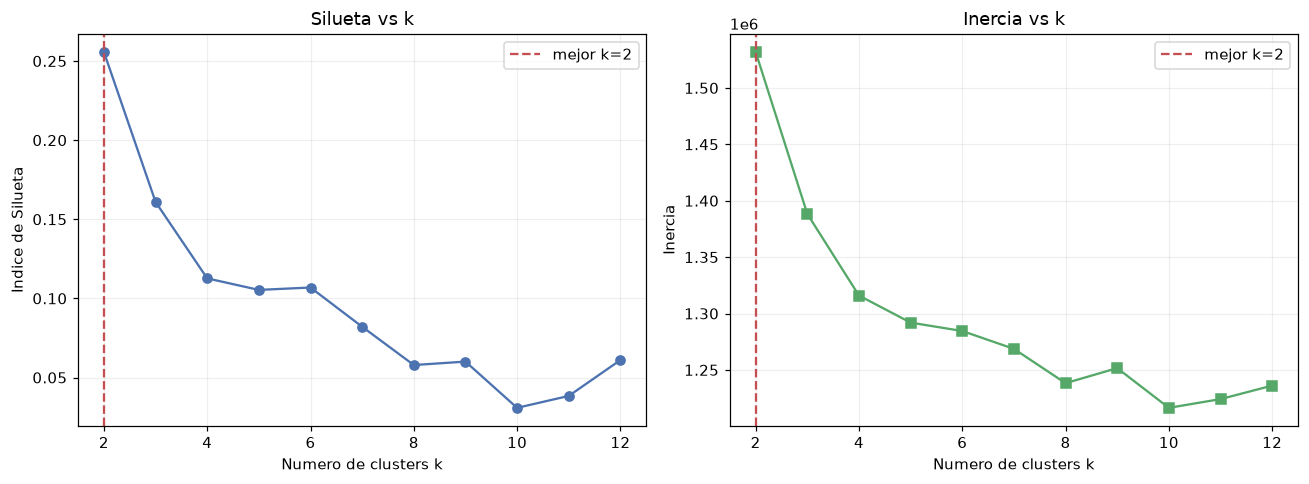

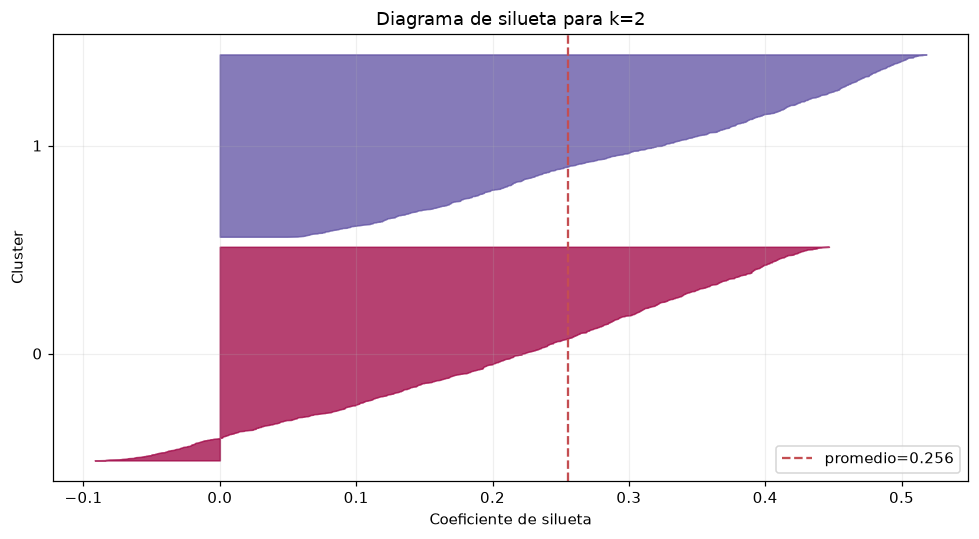

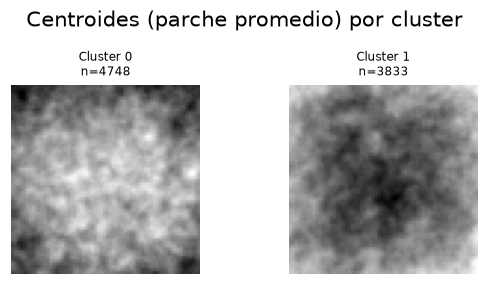

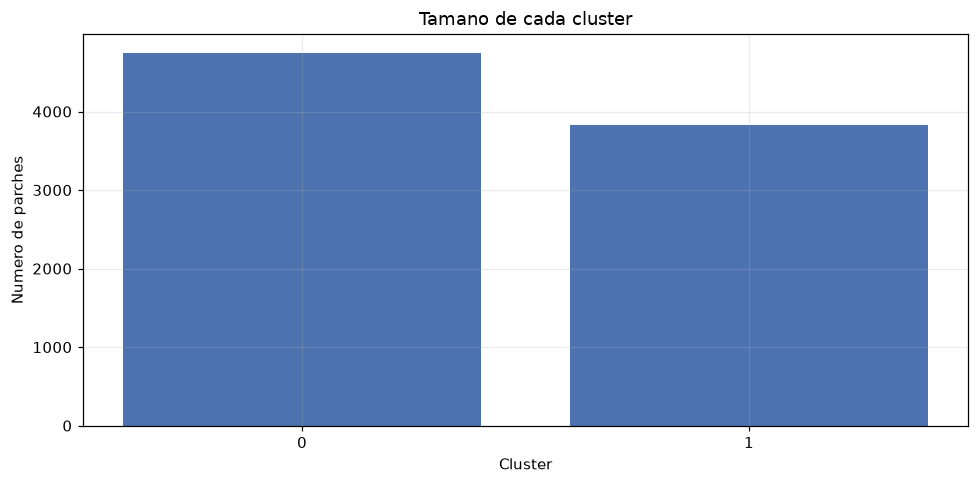

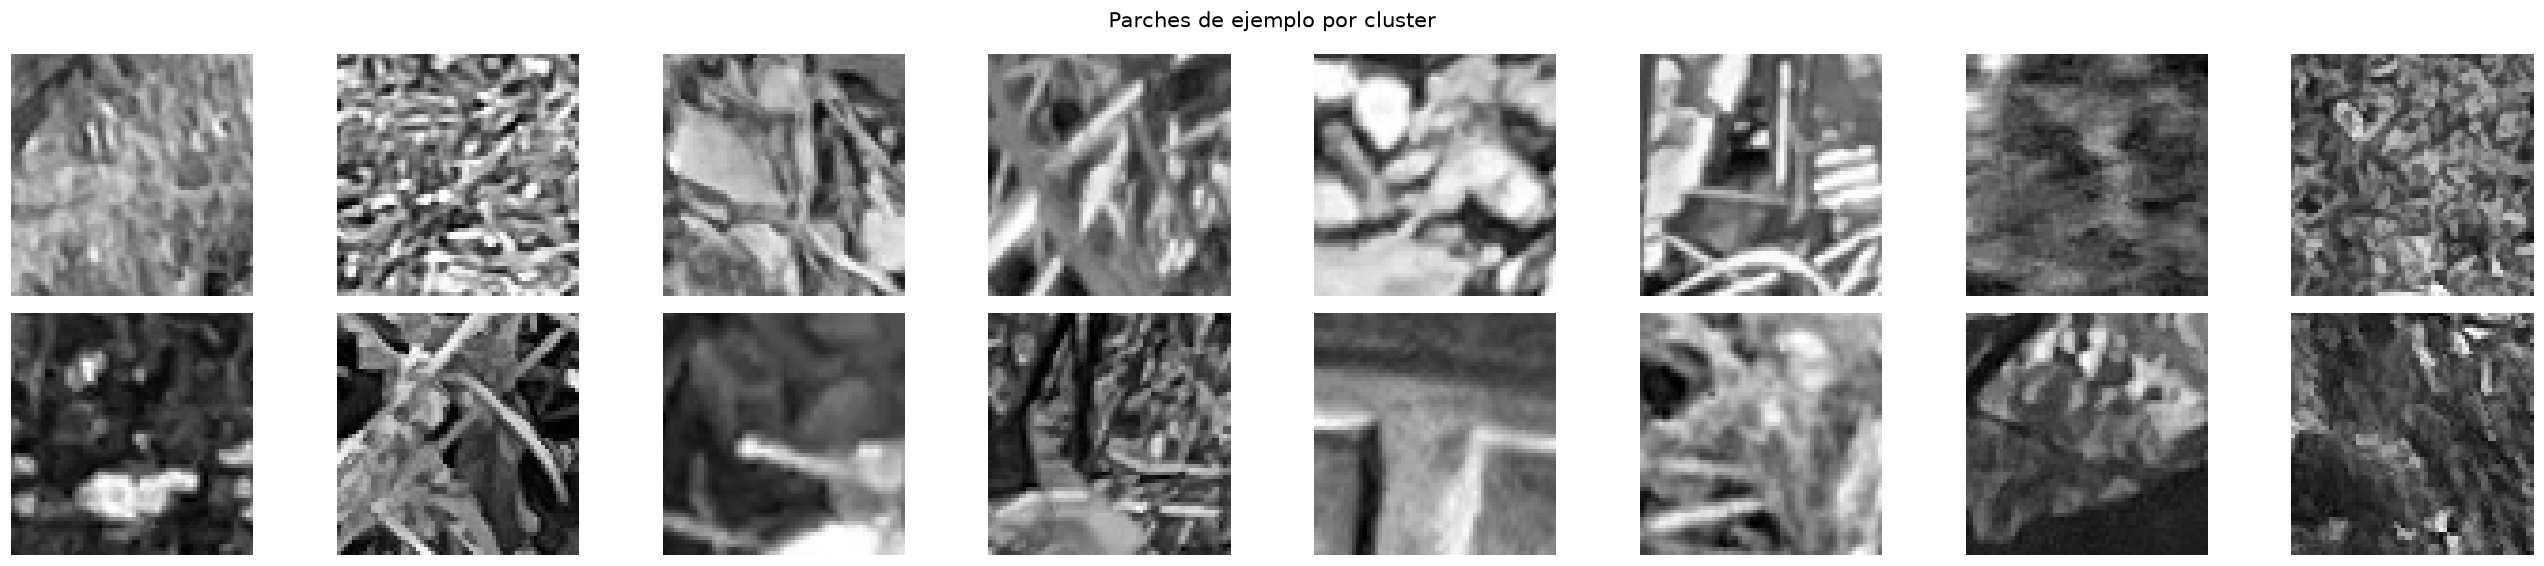

In [9]:
kmeans = nuevo_minibatch(k, SEMILLA, len(X_pool)).fit(X_pool)
etiquetas_cluster = kmeans.labels_
silueta_pool = float(
    silhouette_score(
        X_pool,
        etiquetas_cluster,
        sample_size=int(min(MUESTRA_SILUETA, len(X_pool))),
        random_state=SEMILLA,
    )
)
indices_representantes = obtener_representantes(kmeans, X_pool)

print(f"\nMiniBatchKMeans final con k={k}")
print(f"Silueta del pool: {silueta_pool:.4f}")
print("Tamano de clusters:")
print(pd.Series(etiquetas_cluster).value_counts().sort_index().to_string())

graficar_seleccion_k(df_k, k, FIGURAS / "p1_seleccion_k.png")
graficar_diagrama_silueta(
    X_pool,
    etiquetas_cluster,
    k,
    silueta_pool,
    FIGURAS / "p1_diagrama_silueta.png",
    MUESTRA_SILUETA,
)
graficar_centroides(kmeans, FIGURAS / "p1_centroides.png")
graficar_tamanos_cluster(etiquetas_cluster, FIGURAS / "p1_tamanos_cluster.png")
graficar_parches_por_cluster(
    X_pool, etiquetas_cluster, FIGURAS / "p1_parches_por_cluster.png"
)
plt.show()
plt.close("all")

## 7. Etiquetado interactivo de los parches representativos

Cada representante se muestra como parche ampliado y como imagen completa con
el parche marcado en blanco. La clase se guarda en
`etiquetas_representantes.csv`.

In [10]:
def _bytes_patch(x_plano, indice, tamano=256):
    parche = (x_plano[indice].reshape(TAM_PARCHE, TAM_PARCHE) * 255).astype(np.uint8)
    imagen = Image.fromarray(parche, mode="L").resize(
        (tamano, tamano), Image.Resampling.NEAREST
    )
    buffer = io.BytesIO()
    imagen.convert("RGB").save(buffer, format="JPEG", quality=92)
    return buffer.getvalue()


def _bytes_contexto(ruta, coords, tamano=640):
    imagen = cargar_escala_grises(ruta)
    y, x = int(coords[0]), int(coords[1])
    dibujo = ImageDraw.Draw(imagen)
    dibujo.rectangle(
        [x, y, x + TAM_PARCHE - 1, y + TAM_PARCHE - 1], outline="white", width=6
    )
    imagen.thumbnail((tamano, tamano), Image.Resampling.LANCZOS)
    buffer = io.BytesIO()
    imagen.convert("RGB").save(buffer, format="JPEG", quality=90)
    return buffer.getvalue()


def guardar_etiquetas(df, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    columnas = [
        c
        for c in ["cluster", "indice", "archivo", "y", "x", "n_patches", "clase"]
        if c in df.columns
    ]
    df[columnas].to_csv(ruta, index=False, encoding="utf-8")
    return ruta


def cargar_etiquetas(ruta, df, clave):
    df = df.copy()
    ruta = Path(ruta)
    if not ruta.exists():
        return df
    guardadas = pd.read_csv(ruta, dtype=str, keep_default_na=False)
    guardadas.columns = [c.strip().lower() for c in guardadas.columns]
    if clave not in guardadas.columns or "clase" not in guardadas.columns:
        return df
    mapa = dict(
        zip(
            guardadas[clave].astype(int),
            guardadas["clase"].astype(str).str.strip(),
        )
    )
    df["clase"] = df[clave].map(mapa).fillna(df["clase"]).astype(str).str.strip()
    return df


def crear_etiquetador(df, x_plano, ruta_salida, clases_sugeridas, titulo):
    if not WIDGETS_DISPONIBLES:
        raise RuntimeError(
            "Instale ipywidgets con: uv pip install --python .venv/bin/python "
            "ipywidgets jupyterlab_widgets"
        )

    df = df.copy().reset_index(drop=True)
    ruta_salida = Path(ruta_salida)
    estado = {"pos": 0}

    salida = widgets.Output(
        layout={
            "border": "1px solid #cccccc",
            "min_height": "460px",
            "width": "100%",
        }
    )
    barra = widgets.IntProgress(
        min=0, max=max(1, len(df)), value=0, description="Progreso"
    )
    progreso = widgets.HTML()
    resumen_clases = widgets.HTML()
    clase_texto = widgets.Text(
        description="Clase:",
        placeholder="ej. terreno",
        layout=widgets.Layout(width="320px"),
    )
    clase_existente = widgets.Dropdown(
        options=[""] + sorted(set(str(v) for v in clases_sugeridas)),
        description="Existente:",
        layout=widgets.Layout(width="260px"),
    )
    btn_anterior = widgets.Button(description="Anterior")
    btn_siguiente = widgets.Button(description="Siguiente")
    btn_guardar = widgets.Button(
        description="Guardar y siguiente", button_style="success"
    )
    btn_borrar = widgets.Button(description="Borrar clase", button_style="warning")
    btn_guardar_csv = widgets.Button(description="Guardar CSV", button_style="info")

    def clases_disponibles():
        clases = {str(v).strip() for v in df["clase"] if str(v).strip()}
        clases.update({str(v).strip() for v in clases_sugeridas if str(v).strip()})
        return sorted(clases)

    def actualizar_contadores():
        etiquetadas = int((df["clase"].astype(str).str.strip() != "").sum())
        pendientes = len(df) - etiquetadas
        partes = [
            f"<b>Etiquetados:</b> {etiquetadas}/{len(df)}",
            f"<b>Pendientes:</b> {pendientes}",
        ]
        conteos = df.loc[
            df["clase"].astype(str).str.strip() != "", "clase"
        ].value_counts()
        if len(conteos):
            detalle = " | ".join(f"{c}: {n}" for c, n in conteos.items())
            partes.append(f"<b>Por clase:</b> {detalle}")
        resumen_clases.value = " &nbsp;|&nbsp; ".join(partes)

    def actualizar_clases():
        valor = clase_existente.value
        clase_existente.options = [""] + clases_disponibles()
        if valor in clase_existente.options:
            clase_existente.value = valor

    def mostrar_actual():
        if len(df) == 0:
            with salida:
                clear_output(wait=True)
                print("No hay parches para etiquetar.")
            return
        estado["pos"] = min(max(estado["pos"], 0), len(df) - 1)
        fila = df.iloc[estado["pos"]]
        indice = int(fila["indice"])
        clase_actual = str(fila["clase"]).strip()
        try:
            patch = _bytes_patch(x_plano, indice, 256)
            contexto = _bytes_contexto(
                Path(CARPETA_IMAGENES) / str(fila["archivo"]),
                (fila["y"], fila["x"]),
                640,
            )
            with salida:
                clear_output(wait=True)
                display(
                    widgets.HBox(
                        [
                            widgets.Image(value=patch, format="jpeg", width=256),
                            widgets.Image(value=contexto, format="jpeg", width=420),
                        ]
                    )
                )
                if "cluster" in fila.index and "n_patches" in fila.index:
                    print(
                        f"Cluster {int(fila['cluster'])} | "
                        f"parches en el cluster: {int(fila['n_patches'])}"
                    )
                print(
                    f"Archivo: {fila['archivo']} | y={int(fila['y'])} "
                    f"x={int(fila['x'])}"
                )
                print(
                    f"Clase actual: {clase_actual if clase_actual else '(sin etiquetar)'}"
                )
        except Exception as error:
            with salida:
                clear_output(wait=True)
                print(f"No se pudo cargar el parche: {error}")
        clase_texto.value = clase_actual
        clase_existente.value = (
            clase_actual if clase_actual in clase_existente.options else ""
        )
        barra.max = max(1, len(df))
        barra.value = estado["pos"] + 1
        progreso.value = f"<b>{estado['pos'] + 1} de {len(df)}</b>"
        actualizar_contadores()

    def guardar_y_siguiente(_):
        clase = str(clase_texto.value).strip()
        if not clase:
            with salida:
                print("Escriba o seleccione una clase antes de guardar.")
            return
        df.at[estado["pos"], "clase"] = clase
        guardar_etiquetas(df, ruta_salida)
        actualizar_clases()
        estado["pos"] = min(estado["pos"] + 1, len(df) - 1)
        mostrar_actual()

    def ir_anterior(_):
        estado["pos"] = max(0, estado["pos"] - 1)
        mostrar_actual()

    def ir_siguiente(_):
        estado["pos"] = min(len(df) - 1, estado["pos"] + 1)
        mostrar_actual()

    def borrar_clase(_):
        df.at[estado["pos"], "clase"] = ""
        guardar_etiquetas(df, ruta_salida)
        actualizar_clases()
        mostrar_actual()

    def guardar_csv(_):
        guardar_etiquetas(df, ruta_salida)
        with salida:
            print(f"Etiquetas guardadas en: {ruta_salida}")

    def elegir_existente(change):
        if change["new"]:
            clase_texto.value = change["new"]

    btn_anterior.on_click(ir_anterior)
    btn_siguiente.on_click(ir_siguiente)
    btn_guardar.on_click(guardar_y_siguiente)
    btn_borrar.on_click(borrar_clase)
    btn_guardar_csv.on_click(guardar_csv)
    clase_existente.observe(elegir_existente, names="value")

    instrucciones = widgets.HTML(
        f"<b>{titulo}.</b> Cada imagen muestra el parche y la imagen completa "
        "con el parche marcado en blanco. Escriba o elija la clase del parche."
    )
    controles = widgets.HBox([clase_texto, clase_existente])
    botones = widgets.HBox(
        [btn_anterior, btn_siguiente, btn_guardar, btn_borrar, btn_guardar_csv]
    )
    panel = widgets.VBox(
        [
            instrucciones,
            controles,
            botones,
            barra,
            progreso,
            resumen_clases,
            salida,
        ]
    )
    mostrar_actual()
    return panel

In [11]:
validos = indices_representantes >= 0
clusters_validos = np.arange(kmeans.n_clusters)[validos]
indices_validos = indices_representantes[validos]
conteos_cluster = np.bincount(etiquetas_cluster, minlength=kmeans.n_clusters)
df_reps = pd.DataFrame(
    {
        "cluster": clusters_validos.astype(int),
        "indice": indices_validos.astype(int),
        "archivo": archivos_pool[indices_validos].astype(str),
        "y": coords_pool[indices_validos, 0].astype(int),
        "x": coords_pool[indices_validos, 1].astype(int),
        "n_patches": conteos_cluster[clusters_validos].astype(int),
        "clase": "",
    }
)
df_reps = cargar_etiquetas(ETIQUETAS_REPRESENTANTES, df_reps, "cluster")

if MODO_PRUEBA:
    df_reps["clase"] = [f"grupo_{int(c)}" for c in df_reps["cluster"]]
    guardar_etiquetas(df_reps, ETIQUETAS_REPRESENTANTES)

print("Representantes por cluster")
print(df_reps.to_string(index=False))

if not MODO_PRUEBA:
    display(
        crear_etiquetador(
            df_reps,
            X_pool,
            ETIQUETAS_REPRESENTANTES,
            CLASES_SUGERIDAS,
            "Etiquetado de representantes",
        )
    )

Representantes por cluster
 cluster  indice       archivo    y    x  n_patches clase
       0     305 IMG_3714.HEIC 3237 2859       4748  muro
       1    7845 IMG_3872.HEIC  133 2816       3833  muro


## 8. Carga de etiquetas de representantes

Despues de etiquetar los representantes y pulsar **Guardar CSV**, ejecute esta
celda para cargar las etiquetas y construir el mapa de clases por cluster.

Etiquetas de representantes cargadas
Cluster  0 -> muro
Cluster  1 -> muro
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_representantes.png
Figura guardada en: /home/zahir/SIS420-LABS/part2/resultados_punto1_v2/figuras/p1_contexto_representantes.png


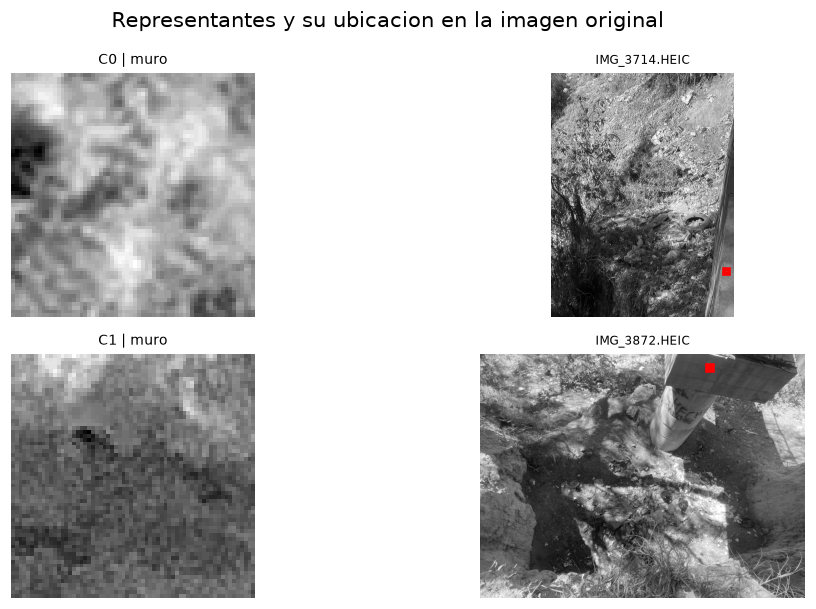

In [12]:
df_reps = cargar_etiquetas(ETIQUETAS_REPRESENTANTES, df_reps, "cluster")
y_representantes = np.full(kmeans.n_clusters, None, dtype=object)
for _, fila in df_reps.iterrows():
    clase = str(fila["clase"]).strip()
    if clase:
        y_representantes[int(fila["cluster"])] = clase

mapa_cluster_a_clase = {
    cluster: clase for cluster, clase in enumerate(y_representantes) if clase
}
if not mapa_cluster_a_clase:
    raise RuntimeError("Etiquete al menos un representante antes de continuar")

print("Etiquetas de representantes cargadas")
for cluster, clase in enumerate(y_representantes):
    print(f"Cluster {cluster:2d} -> {clase if clase else '(sin etiquetar)'}")

graficar_representantes(
    X_pool,
    indices_representantes,
    y_representantes,
    FIGURAS / "p1_representantes.png",
)
graficar_contexto_representantes(
    df_reps, X_pool, CARPETA_IMAGENES, FIGURAS / "p1_contexto_representantes.png"
)
plt.show()
plt.close("all")

## 9. Etiquetado interactivo del conjunto de prueba

Se muestran parches de las escenas reservadas para prueba, muestreados por
cluster predicho (`PARCHES_TEST_POR_CLUSTER` por cluster) para cubrir todos los
grupos. Etiquete al menos unos pocos por clase y pulse **Guardar CSV**. Las
etiquetas quedan en `etiquetas_test.csv`.

In [13]:
etiquetas_test_pred = kmeans.predict(X_test)
indices_test = []
for cluster in range(kmeans.n_clusters):
    miembros = np.where(etiquetas_test_pred == cluster)[0]
    rng_cluster = np.random.default_rng(SEMILLA + 1 + cluster)
    elegidos = rng_cluster.choice(
        miembros,
        size=min(PARCHES_TEST_POR_CLUSTER, len(miembros)),
        replace=False,
    )
    indices_test.append(elegidos)
indices_test = np.sort(np.concatenate(indices_test).astype(int))

df_test_parches = pd.DataFrame(
    {
        "indice": indices_test,
        "cluster": etiquetas_test_pred[indices_test].astype(int),
        "archivo": archivos_test[indices_test].astype(str),
        "y": coords_test[indices_test, 0].astype(int),
        "x": coords_test[indices_test, 1].astype(int),
        "clase": "",
    }
)
df_test_parches = cargar_etiquetas(ETIQUETAS_TEST, df_test_parches, "indice")

if MODO_PRUEBA:
    df_test_parches["clase"] = [
        mapa_cluster_a_clase.get(int(c), "sin_etiqueta")
        for c in etiquetas_test_pred[indices_test]
    ]
    guardar_etiquetas(df_test_parches, ETIQUETAS_TEST)

print("Parches de prueba a etiquetar")
print(df_test_parches.to_string(index=False))

if not MODO_PRUEBA:
    display(
        crear_etiquetador(
            df_test_parches,
            X_test,
            ETIQUETAS_TEST,
            sorted(mapa_cluster_a_clase.values()),
            "Etiquetado del conjunto de prueba",
        )
    )

Parches de prueba a etiquetar
 indice  cluster          archivo    y    x   clase
     56        0 IMG_3702(1).HEIC  693  610        
    112        0    IMG_3703.HEIC  203 2140        
    198        1    IMG_3704.HEIC 1870 1630        
    289        1    IMG_3705.HEIC 3741 2079        
    361        1    IMG_3707.HEIC  467 3842        
    527        1    IMG_3819.HEIC 3898  509        
    562        0    IMG_3821.HEIC 1775 1728        
    707        0    IMG_3823.HEIC 2173 3182        
    820        1    IMG_3825.HEIC 1810  357        
   1016        0    IMG_3828.HEIC 2332 2127        
   1084        1    IMG_3829.HEIC 3170  293        
   1140        0    IMG_3830.HEIC 3935 2568        
   1223        0    IMG_3832.HEIC 1328  628        
   1355        0    IMG_3834.HEIC 1795   67        
   1377        0    IMG_3834.HEIC 2537 2353        
   1468        1    IMG_3836.HEIC  676  903        
   1472        1    IMG_3836.HEIC  928 2381        
   1510        0    IMG_3836.HEIC 

## 10. Conjunto de prueba etiquetado

In [14]:
df_test_parches = cargar_etiquetas(ETIQUETAS_TEST, df_test_parches, "indice")
mascara_test = df_test_parches["clase"].astype(str).str.strip() != ""
if not mascara_test.any():
    raise RuntimeError("Etiquete al menos un parche del conjunto de prueba")

indices_test_etq = df_test_parches.loc[mascara_test, "indice"].to_numpy(dtype=int)
X_test_etq = X_test[indices_test_etq]
y_test_etq = df_test_parches.loc[mascara_test, "clase"].to_numpy(dtype=object)

print(f"Parches de prueba etiquetados: {len(y_test_etq)}")
print(pd.Series(y_test_etq).value_counts().to_string())

df_test_resumen = pd.DataFrame(
    {
        "clase": pd.Series(y_test_etq).value_counts().index,
        "n_parches": pd.Series(y_test_etq).value_counts().values,
    }
)
df_test_resumen["n_imagenes"] = [
    len(np.unique(np.asarray(archivos_test)[indices_test_etq][y_test_etq == clase]))
    for clase in df_test_resumen["clase"]
]
df_test_resumen.to_csv(SALIDA / "resumen_test.csv", index=False, encoding="utf-8")
print("\nClases en el conjunto de prueba (etiquetadas)")
print(df_test_resumen.to_string(index=False))

Parches de prueba etiquetados: 1
terreno    1

Clases en el conjunto de prueba (etiquetadas)
  clase  n_parches  n_imagenes
terreno          1           1


## 11. Propagacion semi-supervisada y clasificadores

In [15]:
def propagar_etiquetas(etiquetas_cluster, y_representantes):
    y_propagadas = np.empty(len(etiquetas_cluster), dtype=object)
    for cluster, etiqueta in enumerate(y_representantes):
        if etiqueta is None:
            continue
        miembros = etiquetas_cluster == cluster
        if miembros.any():
            y_propagadas[miembros] = etiqueta
    mascara = np.asarray(
        [isinstance(valor, str) and valor != "" for valor in y_propagadas]
    )
    return y_propagadas, mascara


def nuevo_clasificador(semilla):
    return LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=semilla
    )


def entrenar_modelo(x, y, semilla):
    if len(np.unique(y)) < 2:
        raise RuntimeError(
            "Se necesitan al menos dos clases distintas para entrenar. "
            "Etiquete al menos dos representantes con clases diferentes."
        )
    return nuevo_clasificador(semilla).fit(x, y)


def muestra_estratificada(y, n, rng):
    clases_unicas = np.unique(y)
    if len(clases_unicas) < 2:
        return rng.choice(len(y), size=min(n, len(y)), replace=False)
    indices = []
    for clase in clases_unicas:
        candidatos = np.where(y == clase)[0]
        indices.append(int(rng.choice(candidatos)))
    restantes = np.setdiff1d(np.arange(len(y)), np.asarray(indices, dtype=int))
    if len(indices) < n and len(restantes) > 0:
        extra = rng.choice(
            restantes, size=min(n - len(indices), len(restantes)), replace=False
        )
        indices.extend(extra.tolist())
    return np.asarray(indices, dtype=int)


def calcular_metricas(nombre, clasificador, x, y, clases):
    y_pred = clasificador.predict(x)
    exactitud = float(accuracy_score(y, y_pred))
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y, y_pred, labels=clases, average="macro", zero_division=0
    )
    precision_pesada, recall_pesada, f1_pesada, _ = precision_recall_fscore_support(
        y, y_pred, labels=clases, average="weighted", zero_division=0
    )
    return {
        "modelo": nombre,
        "exactitud": exactitud,
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "precision_weighted": float(precision_pesada),
        "recall_weighted": float(recall_pesada),
        "f1_weighted": float(f1_pesada),
    }


def promedio_metricas(lista_metricas):
    claves_numericas = [c for c in lista_metricas[0] if c != "modelo"]
    resultado = {"modelo": lista_metricas[0]["modelo"]}
    for clave in claves_numericas:
        resultado[clave] = float(np.mean([fila[clave] for fila in lista_metricas]))
    return resultado

In [16]:
y_propagadas, mascara_propagada = propagar_etiquetas(
    etiquetas_cluster, y_representantes
)
if not mascara_propagada.any():
    raise RuntimeError("No fue posible propagar etiquetas desde los representantes")

X_train = X_pool[mascara_propagada]
y_train = y_propagadas[mascara_propagada]

if len(np.unique(y_train)) < 2:
    raise RuntimeError(
        "La propagacion genero una sola clase. Etiquete al menos dos "
        "representantes con clases diferentes antes de continuar."
    )

clases = np.asarray(sorted(set(y_train) | set(y_test_etq)))

faltantes_test = sorted(set(y_test_etq) - set(y_train))
if faltantes_test:
    print(f"Aviso: clases del test que no estan en el entrenamiento: {faltantes_test}")

reps_etiquetados = df_reps[df_reps["clase"].astype(str).str.strip() != ""]
indices_reps_etq = reps_etiquetados["indice"].to_numpy(dtype=int)
y_reps_etq = reps_etiquetados["clase"].to_numpy(dtype=object)

clf_reps = entrenar_modelo(X_pool[indices_reps_etq], y_reps_etq, SEMILLA)
clf_base = entrenar_modelo(X_train, y_train, SEMILLA)

probas = clf_base.predict_proba(X_train)
confianza = probas.max(axis=1)
n_inciertas = max(2, int(round(FRAC_INCIERTAS * len(X_train))))
n_inciertas = min(n_inciertas, len(X_train))
idx_inciertas = np.argsort(confianza)[:n_inciertas]
while len(np.unique(y_train[idx_inciertas])) < 2 and n_inciertas < len(X_train):
    n_inciertas += 1
    idx_inciertas = np.argsort(confianza)[:n_inciertas]
clf_inciertas = entrenar_modelo(
    X_train[idx_inciertas], y_train[idx_inciertas], SEMILLA + 100
)

print(f"Parches con etiqueta propagada: {int(mascara_propagada.sum())} / {len(X_pool)}")
print(f"Muestras mas inciertas seleccionadas: {n_inciertas}")

df_clases = pd.DataFrame(
    {
        "clase": pd.Series(y_train).value_counts().index,
        "n_parches": pd.Series(y_train).value_counts().values,
    }
)
df_clases["n_imagenes"] = [
    len(np.unique(np.asarray(archivos_pool)[mascara_propagada][y_train == clase]))
    for clase in df_clases["clase"]
]
df_clases["n_clusters"] = [
    int(sum(1 for c in y_representantes if c == clase)) for clase in df_clases["clase"]
]
df_clases.to_csv(SALIDA / "resumen_clases.csv", index=False, encoding="utf-8")
print("\nClases en el entrenamiento (propagadas)")
print(df_clases.to_string(index=False))

RuntimeError: La propagacion genero una sola clase. Etiquete al menos dos representantes con clases diferentes antes de continuar.

## 12. Evaluacion y aprendizaje activo

In [ ]:
def graficar_comparacion_modelos(df_metricas, ruta):
    df = df_metricas.copy()
    etiquetas = df["modelo"].astype(str).tolist()
    x = np.arange(len(df))
    ancho = 0.2
    columnas = ["exactitud", "precision_macro", "recall_macro", "f1_macro"]
    fig, ax = plt.subplots(figsize=(max(10, 1.2 * len(df)), 5))
    for posicion, columna in enumerate(columnas):
        ax.bar(x + (posicion - 1.5) * ancho, df[columna], width=ancho, label=columna)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, rotation=25, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Valor")
    ax.set_title("Comparacion de modelos")
    ax.legend(ncol=2)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_confusion(y, y_pred, clases, ruta, titulo):
    matriz = confusion_matrix(y, y_pred, labels=clases)
    cantidad = len(clases)
    fig, ax = plt.subplots(
        figsize=(max(6, 0.7 * cantidad + 3), max(5, 0.65 * cantidad + 3))
    )
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_xticks(np.arange(cantidad))
    ax.set_yticks(np.arange(cantidad))
    ax.set_xticklabels(clases, rotation=45, ha="right")
    ax.set_yticklabels(clases)
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    if cantidad <= 15:
        umbral = matriz.max() / 2 if matriz.max() > 0 else 0
        for i in range(cantidad):
            for j in range(cantidad):
                ax.text(
                    j,
                    i,
                    str(matriz[i, j]),
                    ha="center",
                    va="center",
                    color="white" if matriz[i, j] > umbral else "black",
                    fontsize=9,
                )
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    return guardar_fig(ruta)

In [ ]:
metricas = []
metricas.append(
    calcular_metricas(
        f"solo_representantes_{len(indices_reps_etq)}",
        clf_reps,
        X_test_etq,
        y_test_etq,
        clases,
    )
)
metricas.append(
    calcular_metricas(
        f"propagacion_kmeans_k{k}",
        clf_base,
        X_test_etq,
        y_test_etq,
        clases,
    )
)
metricas.append(
    calcular_metricas(
        f"activo_inciertas_{n_inciertas}",
        clf_inciertas,
        X_test_etq,
        y_test_etq,
        clases,
    )
)

metricas_aleatorias = []
for repeticion in range(REPETICIONES_ACTIVO):
    idx_aleatorio = muestra_estratificada(
        y_train, n_inciertas, np.random.default_rng(SEMILLA + repeticion)
    )
    clf_aleatorio = entrenar_modelo(
        X_train[idx_aleatorio], y_train[idx_aleatorio], SEMILLA + repeticion
    )
    metricas_aleatorias.append(
        calcular_metricas(
            f"aleatorio_{len(idx_aleatorio)}",
            clf_aleatorio,
            X_test_etq,
            y_test_etq,
            clases,
        )
    )
metricas.append(promedio_metricas(metricas_aleatorias))

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(SALIDA / "metricas_modelos.csv", index=False, encoding="utf-8")
print("Metricas de evaluacion")
print(df_metricas.to_string(index=False))

graficar_comparacion_modelos(df_metricas, FIGURAS / "p1_comparacion_modelos.png")
plt.show()
plt.close("all")

## 13. Matriz de confusion e inciertos

In [ ]:
def graficar_inciertos(x_plano, clasificador, archivos, coords, y, ruta, cantidad=50):
    if clasificador is None or not hasattr(clasificador, "predict_proba"):
        return None
    try:
        probabilidades = clasificador.predict_proba(x_plano)
    except Exception:
        return None
    confianza = probabilidades.max(axis=1)
    predicciones = clasificador.predict(x_plano)
    orden = np.argsort(confianza)[: min(int(cantidad), len(x_plano))]
    columnas = 5
    filas = int(math.ceil(len(orden) / columnas))
    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(3.0 * columnas, 2.6 * filas),
        squeeze=False,
    )
    axes = axes.ravel()
    for ax in axes:
        ax.axis("off")
    registros = []
    for ax, indice in zip(axes, orden):
        ax.imshow(x_plano[indice].reshape(TAM_PARCHE, TAM_PARCHE), cmap="gray")
        ax.set_title(
            f"{predicciones[indice]} | conf={confianza[indice]:.3f}", fontsize=7
        )
        registros.append(
            {
                "indice": int(indice),
                "archivo": str(archivos[indice]),
                "y": int(coords[indice, 0]),
                "x": int(coords[indice, 1]),
                "clase_real": str(y[indice]),
                "clase_predicha": str(predicciones[indice]),
                "confianza": float(confianza[indice]),
            }
        )
    plt.suptitle("Parches mas inciertos segun el modelo", fontsize=14)
    plt.tight_layout()
    guardar_fig(ruta)
    return pd.DataFrame(registros)


def graficar_muestras(x_plano, y, ruta, cantidad=10, titulo="Ejemplos de parches"):
    rng = np.random.default_rng(SEMILLA)
    cantidad = min(cantidad, len(x_plano))
    indices = rng.choice(len(x_plano), size=cantidad, replace=False)
    columnas = min(5, cantidad)
    filas = int(math.ceil(cantidad / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(3.0 * columnas, 3.0 * filas))
    axes = np.atleast_1d(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, indices):
        ax.imshow(x_plano[idx].reshape(TAM_PARCHE, TAM_PARCHE), cmap="gray")
        ax.set_title(str(y[idx]), fontsize=9)
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)

In [ ]:
y_pred_base = clf_base.predict(X_test_etq)
graficar_confusion(
    y_test_etq,
    y_pred_base,
    clases,
    FIGURAS / "p1_matriz_confusion.png",
    "Matriz de confusion del modelo semi-supervisado (propagacion)",
)
plt.show()
plt.close("all")

graficar_muestras(
    X_test_etq,
    y_test_etq,
    FIGURAS / "p1_muestras_test.png",
    cantidad=15,
    titulo="Ejemplos de parches del conjunto de prueba",
)
plt.show()
plt.close("all")

inciertos = graficar_inciertos(
    X_train,
    clf_base,
    archivos_pool[mascara_propagada],
    coords_pool[mascara_propagada],
    y_train,
    FIGURAS / "p1_inciertos.png",
    cantidad=50,
)
if inciertos is not None:
    inciertos.to_csv(SALIDA / "inciertos.csv", index=False, encoding="utf-8")
plt.show()
plt.close("all")

reporte = classification_report(
    y_test_etq,
    y_pred_base,
    labels=clases,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(reporte).transpose().to_csv(
    SALIDA / "classification_report.csv",
    encoding="utf-8",
)

## 14. Resumen final

In [ ]:
resumen = {
    "modo_prueba": MODO_PRUEBA,
    "imagenes_pool": int(len(df_pool)),
    "imagenes_test": int(len(df_test)),
    "parches_pool": int(len(X_pool)),
    "parches_test": int(len(X_test)),
    "parches_test_etiquetados": int(len(y_test_etq)),
    "tam_parche": int(TAM_PARCHE),
    "canales": "escala_de_grises",
    "clases": [str(clase) for clase in clases],
    "k": int(k),
    "k_criterio": "silueta",
    "silueta_pool": float(silueta_pool),
    "n_inciertas": int(n_inciertas),
    "representantes": df_reps.to_dict(orient="records"),
    "metricas": metricas,
}
with open(SALIDA / "resumen.json", "w", encoding="utf-8") as archivo:
    json.dump(resumen, archivo, indent=2, ensure_ascii=False, default=str)

print("Resumen guardado en:", SALIDA / "resumen.json")
print(json.dumps(resumen, indent=2, ensure_ascii=False, default=str))

## Lectura de resultados

- El **codo** se lee en la curva de inercia; el `k` se elige por el **maximo
  de silueta** (`argmax`), no por el codo.
- La **verificacion 64x64** se ve en la seccion 4: cada parche se aplana a
  `64 * 64 = 4096` valores, y las figuras de parches muestran imagenes de
  `64 x 64` pixeles recortadas de las fotos originales.
- El **etiquetado de representantes** reemplaza el etiquetado manual de todas
  las imagenes: se etiqueta un parche por cluster y se propaga la clase.
- La **propagacion semi-supervisada** entrena con todos los parches del cluster,
  no solo con el representante.
- El **aprendizaje activo** selecciona los parches de menor confianza con
  `predict_proba` y entrena un clasificador usando unicamente esas muestras.
- La **matriz de confusion** muestra que clases se confunden.

## Como ejecutar

1. Ejecutar las celdas hasta la de etiquetado de representantes.
2. Etiquetar cada representante con una clase y pulsar **Guardar CSV**.
3. Ejecutar la celda de carga de representantes y la del conjunto de prueba.
4. Etiquetar los parches de prueba y pulsar **Guardar CSV**.
5. Ejecutar el resto de las celdas para obtener las metricas y las figuras.